# Scientific Claim Verification Using Dense Retrieval, Evidence Extraction, and Natural Language Inference

**NLP semester project · two-person team · reproducible experimental report**

## Abstract

We study scientific claim verification on the official SciFact corpus using lexical retrieval, pretrained
sentence embeddings, task-specific contrastive fine-tuning, hybrid rank fusion, and neural reranking.
A trained sentence selector and binary stance classifier provide evidence and SUPPORT/CONTRADICT predictions;
the pipeline abstains when relevance filters reject all evidence. Oracle interventions diagnose retrieval
and evidence-selection losses. This notebook executes each stage and reports measured results, including
the unmodified official SciFact metrics. The supplied run uses the complete data with compact models on CPU;
larger GPU and repeated-seed configurations are available. Smoke experiments are explicitly excluded from findings.

Outputs below are produced by code, never inserted illustrative scores. The final discussion is generated
from the saved evaluation artifacts so it stays consistent with the selected execution configuration.

## 1. Configuration and reproducibility

Run from the repository root. Locally, create the virtual environment described in README.md and select its
kernel. In Colab, upload/clone this complete directory, change to its root, and install requirements first
(`%pip install -r requirements.txt`), then restart the runtime. GPU detection is automatic.

`MODE='full'` is the intended research path. `smoke` checks the whole workflow using 40 training claims,
16 validation claims, 16 dev claims, and a reduced corpus. `extended` allows longer training; run
`scripts/run_seeded.py` for three seeds on the same split. A run directory is immutable with respect to its
configuration: choose a new directory when changing hyperparameters. Re-execution reuses checkpoints and caches.

In [1]:
from pathlib import Path
import os, sys, json
assert Path('scifact_project').is_dir(), 'Change working directory to the project root first.'
from scifact_project.config import Config
MODE = 'smoke'
PROFILE = 'auto'                 # cpu uses MiniLM pair models; gpu uses SciBERT
SEED = 42
config = Config.for_mode(MODE, PROFILE, SEED).prepare()
from scifact_project.experiment import Study
study = Study(config)
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
pd.set_option('display.max_columns', 16)
display(pd.DataFrame([config.dictionary()]).T.rename(columns={0: 'value'}))
display(Markdown(f'Actual device: **{config.device}**. Mode: **{MODE}**. Results: `{config.output_dir}`.'))

/opt/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,value
mode,smoke
profile,gpu
seed,42
split_seed,42
data_dir,data/raw/data
output_dir,outputs/smoke_gpu_seed42
dense_model,sentence-transformers/all-MiniLM-L6-v2
pair_model,allenai/scibert_scivocab_uncased
reranker_model,cross-encoder/ms-marco-MiniLM-L6-v2
dense_epochs,1


Actual device: **cuda**. Mode: **smoke**. Results: `outputs/smoke_gpu_seed42`.

## 2. Problem and research questions

For claim $q$ and a corpus of abstracts, produce evidence-bearing documents, sentence indices, and
document-level stances. A claim verdict is aggregated separately; absence of accepted evidence gives
NOT ENOUGH INFO. Scientific support is relative to the corpus and annotations, not a claim of universal truth.

The main question is how retrieval choices change scientific evidence retrieval and final verification.
We hypothesize that lexical and dense rankings complement each other, task supervision helps pretrained
embeddings, hard negatives improve early precision, and reranking improves small-K ranking. These are hypotheses,
not presumed findings. We also ask whether evidence selection or stance is the dominant downstream bottleneck.

Pipeline: claim → retrieval → cross-encoder reranking → sentence selection → binary stance → evidence-filtered
claim aggregation. Each stage has its own evaluation and saved predictions.

## 3. Official SciFact data and annotation semantics

The archive is downloaded from the official AllenAI S3 release. SHA-256 checksums, split IDs and model revisions
are saved. Corpus IDs remain integers; evidence JSON object keys are their exact decimal strings. Abstract
sentences are never split again or renumbered. `evidence` defines relevance; `cited_doc_ids` does not.

Training/dev claims with empty evidence have no annotated evidence, whereas test claims have **missing** labels.
Test is never evaluated. Each claim-document annotation can contain several alternative rationale sets;
each set can require several sentences together. We preserve these sets for stance examples and official scoring.

Completed data


,split,claims,evaluable_retrieval_claims,SUPPORT,CONTRADICT,NOT_ENOUGH_INFO,support_rationales,contradict_rationales
0,original_train,809,505.0,332.0,173.0,304.0,616.0,341.0
1,internal_train,40,20.0,14.0,6.0,20.0,25.0,10.0
2,internal_validation,16,9.0,5.0,4.0,7.0,11.0,12.0
3,official_dev,16,12.0,7.0,5.0,4.0,10.0,8.0
4,unlabeled_test,300,NaN,NaN,NaN,NaN,NaN,NaN


,words,sentences
count,154.00,154.00
mean,233.12,8.87
std,89.12,3.28
min,69.00,3.00
25%,168.00,6.00
50%,221.50,9.00
75%,284.75,11.00
max,640.00,19.00


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
dev,16.0,11.12,4.36,6.0,8.0,10.0,15.0,21.0
train,809.0,12.84,4.88,3.0,9.0,12.0,16.0,41.0


count  mean  max
split label                       
dev   CONTRADICT      8  1.12    2
      SUPPORT        10  1.20    2
train CONTRADICT    341  1.07    3
      SUPPORT       616  1.07    4

source                                 https://scifact.s3-us-west-2.amazonaws.com/rel...
split_seed                                                                            42
grouping                               Connected components sharing any cited documen...
excluded_train_exact_dev_duplicates                                          [871, 1291]
group_count                                                                          490
test_unlabeled                                                                      True
dtype: object

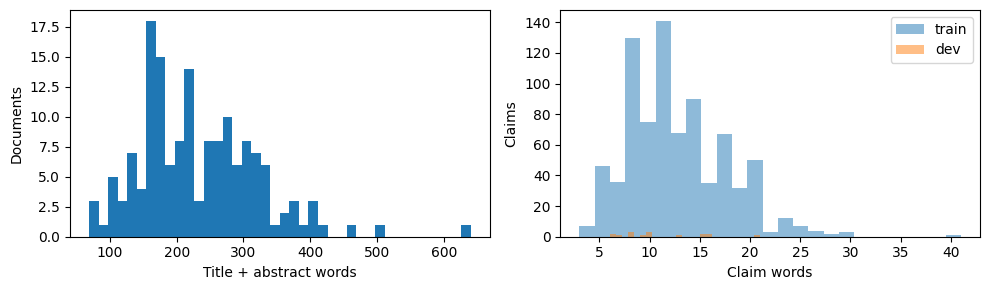

In [2]:
summary, documents, claims, rationales = study.eda()
display(summary)
display(documents[['words', 'sentences']].describe().round(2))
display(claims.groupby('split')['words'].describe().round(2))
display(rationales.groupby(['split', 'label'])['sentences'].agg(['count', 'mean', 'max']).round(2))
display(pd.Series(study.dataset.manifest).drop(['sha256', 'train_ids', 'validation_ids', 'dev_ids']))
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(documents['words'], bins=40)
axes[0].set(xlabel='Title + abstract words', ylabel='Documents')
for split in ['train', 'dev']:
    axes[1].hist(claims.loc[claims.split == split, 'words'], bins=25, alpha=.5, label=split)
axes[1].set(xlabel='Claim words', ylabel='Claims')
axes[1].legend(); plt.tight_layout(); plt.show()

In [3]:
# Real support and contradiction examples from training annotations.
examples = []
for label in ['SUPPORT', 'CONTRADICT']:
    for c in study.dataset.train:
        matches = [(doc, r) for doc, rs in c.get('evidence', {}).items() for r in rs if r['label'] == label]
        if matches:
            doc, rationale = matches[0]
            examples.append({'claim_id': c['id'], 'claim': c['claim'], 'label': label, 'doc_id': int(doc),
                             'original_indices': rationale['sentences'], 'evidence': ' '.join(
                                 study.dataset.corpus[int(doc)]['abstract'][i] for i in rationale['sentences'])})
            break
display(pd.DataFrame(examples))

,claim_id,claim,label,doc_id,original_indices,evidence
0,9,32% of liver transplantation programs required...,SUPPORT,44265107,[15],Policies requiring discontinuation of methadon...
1,2,1 in 5 million in UK have abnormal PrP positiv...,CONTRADICT,13734012,[4],"RESULTS Of the 32,441 appendix samples 16 were..."


## 4. Methodology and evaluation definitions

We form an internal validation split from original training claims using connected components that share
cited papers or identical normalized claim text. This keeps related claim variants together. The official dev
texts are used only to remove exact duplicated training copies; dev evidence labels never enter training,
negative mining, or tuning. The official train/dev split still shares corpus documents, as is normal for retrieval.

Recall@K is the macro mean fraction of a claim's gold documents retrieved. Hit@10 is the mean indicator that
at least one gold document appears in the first 10. MRR@10 uses the reciprocal rank of the first relevant document,
with zero for a miss. Retrieval excludes claims without evidence because their recall denominator is zero.
nDCG@10 has binary relevance. Evidence overlap is micro-averaged; best-rationale recall at a sentence budget
averages over annotated claim-document pairs, choosing the best covered alternative rationale.

Official SciFact abstract correctness requires the correct stance **and a complete gold rationale contained
in the first three predicted sentences**. Sentence correctness requires the whole rationale, not partial overlap.
The vendored evaluator is unmodified and tested against the official documentation's example. Claim accuracy/F1
are simplified project metrics using a documented aggregation rule; they are not official SciFact scores.

In [4]:
import subprocess
checked = subprocess.run([sys.executable, '-m', 'pytest', '-q'], capture_output=True, text=True, check=True)
print(checked.stdout)

...........                                                              [100%]
11 passed in 4.17s



## 5. Experiment A: BM25

BM25Okapi uses lowercase regex word tokens with default $k_1=1.5$, $b=0.75$. We compare abstract only with
title + abstract. No stemming or domain-specific stopword rules are added. All neural comparisons use the
same claim IDs, corpus, gold documents and metric implementation. The following table is internal validation only.

In [5]:
display(study.bm25().round(4))

Completed bm25


,evaluable_claims,Recall@1,Recall@3,Recall@5,Recall@10,Recall@20,Hit@10,MRR@10,nDCG@10
experiment,,,,,,,,,
bm25_abstract,9,0.8889,1.0,1.0,1.0,1.0,1.0,0.9444,0.959
bm25_title_abstract,9,0.7778,1.0,1.0,1.0,1.0,1.0,0.8889,0.918


## 6. Experiment B: pretrained dense retrieval

all-MiniLM-L6-v2 produces mean-pooled, L2-normalized vectors with cosine search in memory. Corpus embeddings
are cached with corpus text and truncation fingerprints. We keep the model's 256-token document limit in full
mode and use batched inference. Dense query scores are meaningful only within the same model/configuration.

SPECTER2 uses its document proximity adapter and its distinct ad-hoc query adapter, CLS pooling and 512 tokens,
following the official model cards. Documents concatenate title, tokenizer separator, and abstract. It is
scheduled after the core stages so an optional dependency/model failure cannot block the core study. Its full
corpus result, or an explicit failure record, appears in the final retrieval table.

In [6]:
display(study.pretrained().round(4))

Completed pretrained_dense


,evaluable_claims,Recall@1,Recall@3,Recall@5,Recall@10,Recall@20,Hit@10,MRR@10,nDCG@10
experiment,,,,,,,,,
bm25_abstract,9,0.8889,1.0,1.0,1.0,1.0,1.0,0.9444,0.959
bm25_title_abstract,9,0.7778,1.0,1.0,1.0,1.0,1.0,0.8889,0.918
dense_pretrained,9,0.8889,1.0,1.0,1.0,1.0,1.0,0.9444,0.959


## 7. Experiment C1: contrastive training with random negatives

Each positive is an annotated evidence abstract, regardless of SUPPORT/CONTRADICT. Negatives are sampled from
the remaining corpus. We exclude all known training-family evidence papers and cited papers. These exclusions
do not establish that every remaining paper is a true negative: SciFact annotations are incomplete.

The loss is multi-positive InfoNCE over explicit and in-batch document candidates. Other known positives are
positive targets; protected family documents are masked rather than used as false negatives. Both C1 and C2 start
from the same pretrained checkpoint and use identical seed, positive examples, batch size, schedule and epoch
budget. AdamW, linear warmup/decay, norm-1 gradient clipping, validation checkpointing and patience-based early
stopping are used. Checkpoints maximize validation Recall@10, breaking ties with MRR@10.

In [7]:
display(study.contrastive('random').round(4))
from scifact_project.data import read_jsonl
training_pairs = pd.DataFrame(read_jsonl(config.out / 'tables/retriever_random_pairs.jsonl'))
display(training_pairs[['claim_id', 'claim', 'positive', 'negative', 'negative_mode']].head())

dense random epoch 1 step 1/6 loss=0.0683


/home/innokentiy/code/local/nlp-project/scifact_project/training.py:82: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


dense random validation: {'evaluable_claims': 9, 'Recall@1': 0.8888888888888888, 'Recall@3': 1.0, 'Recall@5': 1.0, 'Recall@10': 1.0, 'Recall@20': 1.0, 'Hit@10': 1.0, 'MRR@10': 0.9444444444444444, 'nDCG@10': 0.9589921948412731}


Completed dense_random


,evaluable_claims,Recall@1,Recall@3,Recall@5,Recall@10,Recall@20,Hit@10,MRR@10,nDCG@10
experiment,,,,,,,,,
bm25_abstract,9,0.8889,1.0,1.0,1.0,1.0,1.0,0.9444,0.959
bm25_title_abstract,9,0.7778,1.0,1.0,1.0,1.0,1.0,0.8889,0.918
dense_pretrained,9,0.8889,1.0,1.0,1.0,1.0,1.0,0.9444,0.959
dense_random,9,0.8889,1.0,1.0,1.0,1.0,1.0,0.9444,0.959


,claim_id,claim,positive,negative,negative_mode
0,2,1 in 5 million in UK have abnormal PrP positiv...,13734012,92308,random
1,9,32% of liver transplantation programs required...,44265107,623486,random
2,12,40mg/day dosage of folic acid and 2mg/day dosa...,33409100,502797,random
3,22,76-85% of people with severe mental disorder r...,6490571,364522,random
4,30,A breast cancer patient's capacity to metaboli...,24341590,356218,random


## 8. Experiment C2: BM25 hard negatives

We sample from the first 20 permissible candidates among BM25's top 100. Positive/family/citation exclusions
are identical to C1. Mining uses training claims only and does not inspect dev annotations. Saved pair manifests
make the exact positive and negative choices auditable. Hard negatives may still be unannotated relevant papers;
we discuss this source of noise rather than interpreting sampled negatives as verified scientific refutations.

In [8]:
display(study.contrastive('hard').round(4))

dense hard epoch 1 step 1/6 loss=0.1742


/home/innokentiy/code/local/nlp-project/scifact_project/training.py:82: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


dense hard validation: {'evaluable_claims': 9, 'Recall@1': 0.8888888888888888, 'Recall@3': 1.0, 'Recall@5': 1.0, 'Recall@10': 1.0, 'Recall@20': 1.0, 'Hit@10': 1.0, 'MRR@10': 0.9444444444444444, 'nDCG@10': 0.9589921948412731}


Completed dense_hard


,evaluable_claims,Recall@1,Recall@3,Recall@5,Recall@10,Recall@20,Hit@10,MRR@10,nDCG@10
experiment,,,,,,,,,
bm25_abstract,9,0.8889,1.0,1.0,1.0,1.0,1.0,0.9444,0.959
bm25_title_abstract,9,0.7778,1.0,1.0,1.0,1.0,1.0,0.8889,0.918
dense_pretrained,9,0.8889,1.0,1.0,1.0,1.0,1.0,0.9444,0.959
dense_random,9,0.8889,1.0,1.0,1.0,1.0,1.0,0.9444,0.959
dense_hard,9,0.8889,1.0,1.0,1.0,1.0,1.0,0.9444,0.959


## 9. Experiment D: hybrid rank fusion

Reciprocal Rank Fusion combines rank positions rather than incompatible raw score scales:
$s(d)=w/(c+r_{BM25}(d))+(1-w)/(c+r_{dense}(d))$, omitting a term when a document is absent.
For each pretrained/random/hard dense retriever we tune c in {10, 60} and w in {0.25, 0.5, 0.75} on
internal validation only, with input depth 50. A trained dense variant is selected for the deployed hybrid
using the same validation criterion. Dev comparisons do not feed back into this choice.

In [9]:
display(study.hybrid().round(4)); display(pd.Series(study.selection))

Completed hybrid


,evaluable_claims,Recall@1,Recall@3,Recall@5,Recall@10,Recall@20,Hit@10,MRR@10,nDCG@10
experiment,,,,,,,,,
bm25_abstract,9,0.8889,1.0,1.0,1.0,1.0,1.0,0.9444,0.959
bm25_title_abstract,9,0.7778,1.0,1.0,1.0,1.0,1.0,0.8889,0.918
dense_pretrained,9,0.8889,1.0,1.0,1.0,1.0,1.0,0.9444,0.959
dense_random,9,0.8889,1.0,1.0,1.0,1.0,1.0,0.9444,0.959
dense_hard,9,0.8889,1.0,1.0,1.0,1.0,1.0,0.9444,0.959
hybrid_pretrained,9,0.8889,1.0,1.0,1.0,1.0,1.0,0.9444,0.959
hybrid_random,9,0.8889,1.0,1.0,1.0,1.0,1.0,0.9444,0.959
hybrid_hard,9,0.8889,1.0,1.0,1.0,1.0,1.0,0.9444,0.959


dense_mode                                                          random
hybrid_name                                                  hybrid_random
rrf_constant                                                            10
rrf_weight                                                            0.25
dense_embeddings_path    outputs/smoke_gpu_seed42/cache/corpus_random_4...
dtype: object

## 10. Experiment E: pretrained cross-encoder reranking

ms-marco-MiniLM-L6-v2 scores claim–document pairs from the selected hybrid's top 20 candidates. This is a
general-domain pretrained relevance model, not a scientific stance classifier. Candidate-set equality is
asserted before/after reranking. We report its per-query scoring cost separately from initial retrieval and
index construction. Its top-20 recall cannot exceed the fixed candidate set's recall.

In [10]:
display(study.reranking().round(4))

Completed reranking


,evaluable_claims,Recall@1,Recall@3,Recall@5,Recall@10,Recall@20,Hit@10,MRR@10,nDCG@10
experiment,,,,,,,,,
bm25_abstract,9,0.8889,1.0,1.0,1.0,1.0,1.0,0.9444,0.959
bm25_title_abstract,9,0.7778,1.0,1.0,1.0,1.0,1.0,0.8889,0.918
dense_pretrained,9,0.8889,1.0,1.0,1.0,1.0,1.0,0.9444,0.959
dense_random,9,0.8889,1.0,1.0,1.0,1.0,1.0,0.9444,0.959
dense_hard,9,0.8889,1.0,1.0,1.0,1.0,1.0,0.9444,0.959
hybrid_pretrained,9,0.8889,1.0,1.0,1.0,1.0,1.0,0.9444,0.959
hybrid_random,9,0.8889,1.0,1.0,1.0,1.0,1.0,0.9444,0.959
hybrid_hard,9,0.8889,1.0,1.0,1.0,1.0,1.0,0.9444,0.959
hybrid_reranked,9,1.0000,1.0,1.0,1.0,1.0,1.0,1.0000,1.000


## 11. Experiment F: supervised evidence extraction

The baseline ranks individual abstract sentences by pretrained embedding cosine similarity to the claim.
The supervised selector trains on claim–sentence pairs with binary labels from the union of alternative gold
rationales. It keeps all positives and samples up to three negatives per positive. Non-rationale sentences and
cited-but-unannotated abstracts provide negatives; the latter are weak labels, recorded by source.

The CPU profile fine-tunes the six-layer MiniLM encoder to complete the study within available resources.
The GPU profile uses SciBERT. Weighted cross entropy handles class imbalance; validation macro F1 selects epochs.
Sentence and pipeline thresholds are subsequently tuned using **retrieved validation documents**, with a maximum
of three sentences per document. We evaluate gold-document and retrieved-document settings and both overlap
and official complete-rationale metrics. Independent classification cannot fully model jointly necessary evidence.

## 12. Experiment G: stance verification

Each complete annotated rationale creates a claim–evidence example labeled SUPPORT or CONTRADICT; alternatives
remain separate. No arbitrary unannotated abstract is assigned an NEI stance. The first simple model is TF-IDF
plus balanced logistic regression. The transformer is independently fine-tuned with the same weighted loss,
scheduling and checkpoint practices as the selector. NEI is handled only by pipeline relevance/confidence filters.

In [11]:
display(study.supervised())

OSError: We couldn't connect to 'https://huggingface.co' to load the files, and couldn't find them in the cached files.
Checkout your internet connection or see how to run the library in offline mode at 'https://huggingface.co/docs/transformers/installation#offline-mode'.

## 13. End-to-end integration and validation-only acceptance tuning

The deployed pipeline verifies the reranked top five documents. It selects up to three sentences above a
validation-tuned selector threshold and predicts binary stance on those sentences in original abstract order.
Stance confidence and relevance-logit thresholds are tuned on internal validation official rationalized F1.
When accepted documents disagree, the claim verdict is the label of the document with largest selector score
times stance probability; ties choose the smallest document ID. This is our aggregation policy, not an official rule.
An empty accepted set yields NOT ENOUGH INFO. Scores are uncalibrated model outputs, not truth probabilities.

In [ ]:
end_to_end = study.final_evaluation()
display(pd.Series(study.selection))
print('All configurations are frozen. Final comparisons below use official dev; test remains unlabeled.')

## 14. Oracle and controlled ablation settings

We compare predicted documents/evidence/stance, gold documents with predicted evidence/stance, and gold
documents with a complete gold rationale and predicted stance. Oracle evidence uses the shortest complete
alternative per document, deterministically. Oracle settings are diagnostics and never enter `predict`.

Two retrieval ablations reuse the trained selector, stance model and sentence/stance thresholds with BM25
or the hybrid before reranking. The hybrid ordering ablation uses the exact same cross-encoder document scores
and acceptance thresholds, so only the ordering changes. BM25 omits that relevance-logit filter; its comparison
has this additional difference. Official scores retain document-level
predictions; a separate table shows simplified aggregate claim metrics.

## 15. Supplementary SPECTER2 experiment

The adapters/Transformers versions are pinned together because the initially installed Transformers 5 release
was not the adapter-compatible environment used here. `scripts/probe_models.py` checks both adapter forward
passes. This cell evaluates the entire current-mode corpus when enabled and records any unavoidable failure.
SPECTER2 is supplementary and never changes the already selected pipeline after dev evaluation.

In [ ]:
study.specter2()
display(study.status.get('specter2'))
retrieval_table = study.save_retrieval_tables()
from scifact_project.report import generate_report
retrieval, evidence, stance, ablations = generate_report(study)

## 16. Final retrieval comparisons (official dev)

In [ ]:
display(retrieval.loc[retrieval.split == 'dev'].drop(columns=['split', 'seed']).set_index('experiment').round(4))
display(Image(filename=str(config.out / 'figures/retrieval_recall.png')))
display(Image(filename=str(config.out / 'figures/retrieval_mrr.png')))

## 17. Evidence, stance, and end-to-end comparisons

In [ ]:
display(evidence.round(4))
display(stance.round(4))
display(ablations.round(4))
for name in ['evidence_selection', 'confusion_matrices', 'end_to_end_ablations']:
    display(Image(filename=str(config.out / 'figures' / f'{name}.png')))
gold_stance = json.loads((config.out / 'metrics/stance_gold.json').read_text())
display(pd.DataFrame(gold_stance['per_class']).T.round(4))

## 18. Data distributions, learning curves, and sampling uncertainty

In [ ]:
for name in ['data_distributions', 'training_curves']:
    display(Image(filename=str(config.out / 'figures' / f'{name}.png')))
display(pd.DataFrame(json.loads((config.out / 'metrics/paired_bootstrap.json').read_text())))

## 19. Measured discussion, five concrete errors, and conclusions

This report is generated from actual saved metrics. Differences are in percentage points, while tables use
fractions. Failure categories are determined from retrieval, selection, and stance outputs; they do not imply
unobserved linguistic explanations. Only one seed is available in the delivered compact run; bootstrap intervals
describe claim sampling uncertainty and cannot replace repeated training seeds.

In [ ]:
display(Markdown((config.out / 'analysis.md').read_text()))

## 20. Working annotation-free prediction

The reusable function loads the selected trained retriever, selector and stance checkpoints. It uses corpus
texts only, with no lookup of claim annotations or citation metadata. A new claim returns a verdict, rankings,
titles, original evidence indices and model scores. The example below is a real execution, not a gold oracle.

In [ ]:
from scifact_project.pipeline import ClaimVerifier
verifier = ClaimVerifier(config, study.dataset, study.selection)
import time
started = time.perf_counter()
prediction = verifier.predict('Antiretroviral therapy reduces rates of tuberculosis.')
print(f'Warm-model single-claim inference: {time.perf_counter() - started:.3f} seconds')
display(prediction)

## Reproduction checklist and semester scope

All core comparisons, checkpoints, pair manifests, rankings, scoring outputs, figures (PNG/PDF), configuration,
package versions and source/model hashes live in the selected `outputs/` run directory. `scripts/execute_notebook.py`
re-executes and validates this notebook. Running it with populated caches displays results without retraining;
change the output directory for a clean run. `scripts/run_seeded.py` supports repeated seeds with a fixed split.

A feasible two-person semester plan is: weeks 1–3 data/metrics/baselines; 4–6 dense training and mining;
7–9 selector/stance training; 10–11 hybrid/reranker integration; 12–13 oracle experiments and repeated seeds;
14–15 manual error review, report and reproducibility audit. The implementation supplies these stages;
stronger GPU models, a scientific reranker, and repeated-seed extensions remain research follow-ups.

## References

- Wadden et al. (2020), [Fact or Fiction: Verifying Scientific Claims](https://aclanthology.org/2020.emnlp-main.609/).
- [Official SciFact repository](https://github.com/allenai/scifact), [data schema](https://github.com/allenai/scifact/blob/master/doc/data.md),
  [evaluation rules](https://github.com/allenai/scifact/blob/master/doc/evaluation.md).
- Reimers & Gurevych (2019), [Sentence-BERT](https://aclanthology.org/D19-1410/);
  [all-MiniLM-L6-v2 model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2).
- Singh et al. (2023), [SciRepEval](https://aclanthology.org/2023.emnlp-main.338/);
  [SPECTER2 document adapter](https://huggingface.co/allenai/specter2),
  [ad-hoc query adapter](https://huggingface.co/allenai/specter2_adhoc_query).
- Beltagy et al. (2019), [SciBERT](https://aclanthology.org/D19-1371/).
- [Cross-encoder ms-marco-MiniLM-L6-v2 model card](https://huggingface.co/cross-encoder/ms-marco-MiniLM-L6-v2).
- Cormack, Clarke & Büttcher (2009), [Reciprocal Rank Fusion](https://doi.org/10.1145/1571941.1572114).
- [SentenceTransformers contrastive loss documentation](https://sbert.net/docs/package_reference/sentence_transformer/losses.html),
  [AdapterHub installation](https://docs.adapterhub.ml/installation.html).